<a href="https://colab.research.google.com/github/samueladian3-cpu/ml-portfolio/blob/main/Fine_tuning_submission_PGABL_Samuel_Adian.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek Akhir: Fine-tuned Chatbot Tim Legal berbasis RAG
## Notebook 1 — Fine-tuning LLM (Kriteria 1: Basic + Skilled)

- **Nama:** Samuel Adian
- **Email Dicoding:** samueladian3@gmail.com
- **Base model:** `unsloth/Qwen2.5-3B-bnb-4bit` (base *text generation*, kuantisasi resmi Unsloth dari penyedia terpercaya Qwen/Alibaba)
- **Dataset:** `Ichsan2895/alpaca-gpt4-indonesian` (WAJIB sesuai instruksi submission)

**Cakupan notebook ini:**
1. **Basic** — mapping dataset ke Chat Template (ChatML), QLoRA 4-bit *double quantization* + LoRA pada komponen Multi-Head Attention & Feed Forward Network, SFTTrainer ≥ 800 steps, push model ke Hugging Face dengan `merged_16bit`.
2. **Skilled** — split train/validation dengan `eval_strategy="steps"` + logging (WandB), dan **2 eksperimen hyperparameter** untuk mencari kurva loss terbaik tanpa overfitting.

> Jalankan di Google Colab / Kaggle dengan GPU T4 (free tier).

## 1. Instalasi Dependensi

In [ ]:
%%capture
!pip install unsloth
!pip install wandb rouge-score

## 2. Konfigurasi Environment Variables (API Keys)

Sesuai ketentuan submission, **API key TIDAK boleh ditulis langsung (hardcode)** di notebook. Kita gunakan **Colab Secrets** (ikon kunci 🔑 di sidebar kiri Colab) lalu simpan ke *environment variables*:
- `HF_TOKEN` → token Hugging Face (role **Write**) dari https://huggingface.co/settings/tokens
- `WANDB_API_KEY` → API key Weights & Biases dari https://wandb.ai/authorize

In [ ]:
import os

# --- Google Colab ---
from google.colab import userdata
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")


HF_USERNAME = "justasamthing"

import wandb
wandb.login(key=os.environ["WANDB_API_KEY"])
print("Environment variables berhasil dikonfigurasi (token tidak tampil di notebook).")

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: samueladian3 (samueladian3-stikom-uyelindo) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Environment variables berhasil dikonfigurasi (token tidak tampil di notebook).


## 3. Memuat Dataset

Dataset instruction (tanya–jawab) format **Alpaca berbahasa Indonesia** yang WAJIB digunakan: [`Ichsan2895/alpaca-gpt4-indonesian`](https://huggingface.co/datasets/Ichsan2895/alpaca-gpt4-indonesian).

In [ ]:
from datasets import load_dataset

dataset = load_dataset("Ichsan2895/alpaca-gpt4-indonesian", split="train")
print(dataset)
print("\nContoh 1 baris dataset MENTAH (BELUM di-mapping):\n")
dataset[0]

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

alpaca-gpt4-indonesia.csv:   0%|          | 0.00/41.4M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/49969 [00:00<?, ? examples/s]

Dataset({
    features: ['Unnamed: 0', 'input', 'output'],
    num_rows: 49969
})

Contoh 1 baris dataset MENTAH (BELUM di-mapping):



{'Unnamed: 0': 1,
 'input': 'Saranlah slogan untuk kampanye daur ulang\n',
 'output': '1. "Kurangi, gunakan kembali, daur ulang: Bersama untuk masa depan yang lebih hijau."\n2. "Daur ulanglah hari ini, untuk masa depan yang lebih baik."\n3. "Ubah sampahmu menjadi harta karun - Daur ulang!"\n4. "Daur ulang untuk siklus kehidupan."\n5. "Simpan sumber daya, daur ulang lebih banyak."'}

## 4. Memuat Base Model dengan QLoRA (4-bit + Double Quantization)

Model dimuat dalam format **4-bit (NF4)** dengan **double quantization** aktif — inilah inti teknik **QLoRA** yang membuat fine-tuning model 3B muat di GPU T4 free tier. Kita buktikan konfigurasi kuantisasinya dengan mencetak `quantization_config`.

In [ ]:
from unsloth import FastLanguageModel
import torch

MAX_SEQ_LENGTH = 1024
BASE_MODEL = "unsloth/Qwen2.5-3B-bnb-4bit"  # base model text generation, kuantisasi resmi Unsloth

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name      = BASE_MODEL,
    max_seq_length  = MAX_SEQ_LENGTH,
    dtype           = None,        # auto (float16 di T4)
    load_in_4bit    = True,        # QLoRA: bobot model dimuat dalam 4-bit
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


Accessing `is_flash_linear_attention_available` from `.models.aria.image_processing_aria`. Returning `is_flash_linear_attention_available` instead. Behavior may be different and this alias will be removed in future versions.
Accessing `is_flash_linear_attention_available` from `.models.aria.image_processing_pil_aria`. Returning `is_flash_linear_attention_available` instead. Behavior may be different and this alias will be removed in future versions.
Accessing `is_flash_linear_attention_available` from `.models.auto.image_processing_auto`. Returning `is_flash_linear_attention_available` instead. Behavior may be different and this alias will be removed in future versions.
Accessing `is_flash_linear_attention_available` from `.models.beit.image_processing_beit`. Returning `is_flash_linear_attention_available` instead. Behavior may be different and this alias will be removed in future versions.
Accessing `is_flash_linear_attention_available` from `.models.beit.image_processing_pil_beit`. R

🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.7.2: Fast Qwen2 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

In [ ]:
# Bukti bahwa model dikuantisasi 4-bit dengan DOUBLE QUANTIZATION aktif
qcfg = model.config.quantization_config
print("load_in_4bit           :", qcfg["load_in_4bit"] if isinstance(qcfg, dict) else qcfg.load_in_4bit)
print("bnb_4bit_quant_type    :", qcfg["bnb_4bit_quant_type"] if isinstance(qcfg, dict) else qcfg.bnb_4bit_quant_type)
print("bnb_4bit_use_double_quant:", qcfg["bnb_4bit_use_double_quant"] if isinstance(qcfg, dict) else qcfg.bnb_4bit_use_double_quant)

load_in_4bit           : True
bnb_4bit_quant_type    : nf4
bnb_4bit_use_double_quant: True


### Menambahkan Adapter LoRA

Adapter LoRA didefinisikan pada **KEDUA komponen komputasi utama** model (instruksi hanya mensyaratkan minimal salah satu, kita pasang keduanya):
- **Multi-Head Attention** → `q_proj`, `k_proj`, `v_proj`, `o_proj`
- **Feed Forward Network** → `gate_proj`, `up_proj`, `down_proj`

In [ ]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 16,
    target_modules = [
        "q_proj", "k_proj", "v_proj", "o_proj",     # Multi-Head Attention
        "gate_proj", "up_proj", "down_proj",        # Feed Forward Network
    ],
    lora_alpha = 16,
    lora_dropout = 0,
    bias = "none",
    use_gradient_checkpointing = "unsloth",  # hemat VRAM, mencegah OOM
    random_state = 42,
)
model.print_trainable_parameters()

Unsloth 2026.7.2 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


## 5. Mapping Dataset ke Chat Template (ChatML)

Sesuai kriteria, kita gunakan fungsi **`.map()` dari Hugging Face `datasets`** untuk mengubah dataset mentah (kolom `instruction`, `input`, `output`) ke standar **Chat Template ChatML** yang didukung Unsloth, lengkap dengan token spesial (`<|im_start|>`, `<|im_end|>`).

In [ ]:
from unsloth.chat_templates import get_chat_template

tokenizer = get_chat_template(tokenizer, chat_template="chatml")

# Cek dulu struktur kolom dataset (bukti untuk reviewer)
print("Kolom dataset:", dataset.column_names)

SYSTEM_PROMPT = (
    "Kamu adalah asisten AI yang membantu menjawab pertanyaan pengguna "
    "dalam bahasa Indonesia secara akurat, jelas, dan sopan."
)

def formatting_prompts_func(examples):
    """Mengubah baris dataset (input = instruksi, output = jawaban) menjadi teks ChatML."""
    texts = []
    for user_content, output in zip(examples["input"], examples["output"]):
        conversation = [
            {"role": "system",    "content": SYSTEM_PROMPT},
            {"role": "user",      "content": user_content},
            {"role": "assistant", "content": output},
        ]
        texts.append(
            tokenizer.apply_chat_template(
                conversation, tokenize=False, add_generation_prompt=False
            )
        )
    return {"text": texts}

dataset_mapped = dataset.map(formatting_prompts_func, batched=True)

Kolom dataset: ['Unnamed: 0', 'input', 'output']


Map:   0%|          | 0/49969 [00:00<?, ? examples/s]

In [ ]:
# Output print SATU baris dataset yang SUDAH di-mapping, lengkap dengan token spesial
print(dataset_mapped[0]["text"])

<|im_start|>system
Kamu adalah asisten AI yang membantu menjawab pertanyaan pengguna dalam bahasa Indonesia secara akurat, jelas, dan sopan.<|im_end|>
<|im_start|>user
Saranlah slogan untuk kampanye daur ulang
<|im_end|>
<|im_start|>assistant
1. "Kurangi, gunakan kembali, daur ulang: Bersama untuk masa depan yang lebih hijau."
2. "Daur ulanglah hari ini, untuk masa depan yang lebih baik."
3. "Ubah sampahmu menjadi harta karun - Daur ulang!"
4. "Daur ulang untuk siklus kehidupan."
5. "Simpan sumber daya, daur ulang lebih banyak."<|im_end|>



## 6. Split Train / Validation (Skilled)

Dataset dibagi menjadi **train** dan **validation** agar kurva *eval loss* dapat dipantau per-steps dan overfitting terdeteksi.

In [ ]:
split = dataset_mapped.train_test_split(test_size=200, seed=42)
train_ds = split["train"]
eval_ds  = split["test"]
print(f"Train: {len(train_ds)} baris | Validation: {len(eval_ds)} baris")

Train: 49769 baris | Validation: 200 baris


## 7. Eksperimen Hyperparameter (Skilled)

Kita lakukan **dua eksperimen training** dengan kombinasi hyperparameter berbeda, masing-masing **800 steps** (memenuhi syarat Basic ≥ 800 steps) dengan:
- `eval_dataset` dimasukkan ke trainer,
- `eval_strategy="steps"` (nama baru dari `evaluation_strategy` di TRL/Transformers terbaru),
- logging ke **Weights & Biases** setiap 25 steps.

| Eksperimen | learning_rate | warmup_steps | weight_decay | lr_scheduler |
|---|---|---|---|---|
| **Exp 1** | 2e-4 | 50 | 0.01 | cosine |
| **Exp 2** | 5e-5 | 100 | 0.1 | linear |

In [ ]:
from trl import SFTTrainer, SFTConfig

def build_trainer(model, tokenizer, run_name, output_dir,
                  learning_rate, warmup_steps, weight_decay, lr_scheduler_type):
    """Membangun SFTTrainer dengan eval_dataset + eval_strategy='steps' + logging."""
    return SFTTrainer(
        model         = model,
        tokenizer     = tokenizer,
        train_dataset = train_ds,
        eval_dataset  = eval_ds,                 # Skilled: eval_dataset dimasukkan
        dataset_text_field = "text",
        max_seq_length = MAX_SEQ_LENGTH,
        args = SFTConfig(
            output_dir  = output_dir,
            run_name    = run_name,
            per_device_train_batch_size = 2,
            gradient_accumulation_steps = 4,
            max_steps      = 800,                # WAJIB: minimal 800 steps
            learning_rate  = learning_rate,
            warmup_steps   = warmup_steps,
            weight_decay   = weight_decay,
            lr_scheduler_type = lr_scheduler_type,
            optim       = "adamw_8bit",          # optimizer hemat memori (anti-OOM)
            fp16        = not torch.cuda.is_bf16_supported(),
            bf16        = torch.cuda.is_bf16_supported(),
            logging_steps = 25,                  # Skilled: logging aktif
            eval_strategy = "steps",             # Skilled: evaluation_strategy = "steps"
            eval_steps    = 200,
            per_device_eval_batch_size = 2,
            save_strategy = "no",
            report_to     = "wandb",             # logger WandB
            seed          = 42,
        ),
    )

In [ ]:
import matplotlib.pyplot as plt

def plot_loss(trainer, title):
    """Plot kurva train loss & eval loss dari log history trainer."""
    hist = trainer.state.log_history
    tr = [(h["step"], h["loss"])      for h in hist if "loss" in h]
    ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]
    plt.figure(figsize=(9, 4))
    plt.plot([s for s, _ in tr], [l for _, l in tr], label="train_loss")
    if ev:
        plt.plot([s for s, _ in ev], [l for _, l in ev], marker="o", label="eval_loss")
    plt.xlabel("step"); plt.ylabel("loss"); plt.title(title)
    plt.legend(); plt.grid(True); plt.show()
    return ev[-1][1] if ev else None

### 7.1 Eksperimen 1 — `lr=2e-4`, warmup 50, weight_decay 0.01, cosine

In [ ]:
trainer1 = build_trainer(
    model, tokenizer,
    run_name="exp1_lr2e-4_cosine", output_dir="outputs_exp1",
    learning_rate=2e-4, warmup_steps=50, weight_decay=0.01, lr_scheduler_type="cosine",
)
stats1 = trainer1.train()

Unsloth: Tokenizing ["text"] (num_proc=6):   0%|          | 0/49769 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=6):   0%|          | 0/200 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 49,769 | Num Epochs = 1 | Total steps = 800
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)


wandb: Detected [huggingface_hub.inference, openai] in use.
wandb: Use W&B Weave for improved LLM call tracing. Install Weave with `pip install weave` then add `import weave` to the top of your script.
wandb: For more information, check out the docs at: https://weave-docs.wandb.ai
`use_return_dict` is deprecated! Use `return_dict` instead!


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
200,1.165066,1.127509
400,1.106630,1.109787
600,1.083321,1.097813
800,1.121111,1.095182


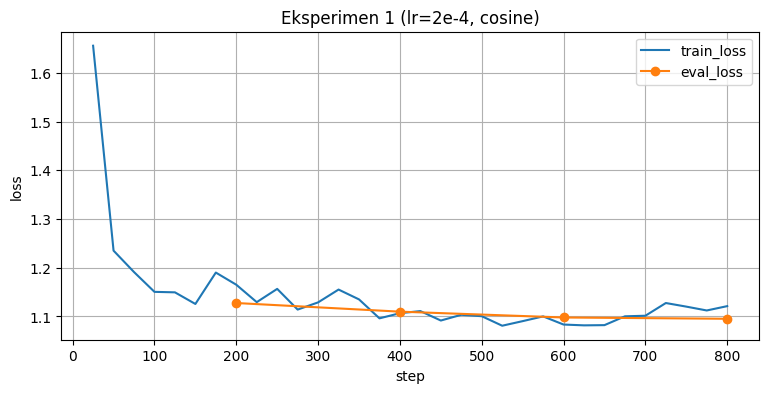

Final eval_loss Exp 1: 1.0951815843582153


Unsloth: Restored added_tokens_decoder metadata in adapter_exp1/tokenizer_config.json.


('adapter_exp1/tokenizer_config.json',
 'adapter_exp1/chat_template.jinja',
 'adapter_exp1/tokenizer.json')

In [ ]:
final_eval_exp1 = plot_loss(trainer1, "Eksperimen 1 (lr=2e-4, cosine)")
print("Final eval_loss Exp 1:", final_eval_exp1)

# Simpan adapter hasil eksperimen 1
model.save_pretrained("adapter_exp1")
tokenizer.save_pretrained("adapter_exp1")

### 7.2 Eksperimen 2 — `lr=5e-5`, warmup 100, weight_decay 0.1, linear

Sebelum eksperimen kedua, model & trainer lama **dihapus dari memori** lalu base model dimuat ulang dari nol agar perbandingan adil dan VRAM tidak menumpuk (sesuai tips submission tentang manajemen memori).

In [ ]:
import gc

del trainer1, model, tokenizer
gc.collect()
torch.cuda.empty_cache()
print("Memori GPU dibersihkan:", round(torch.cuda.memory_allocated()/1e9, 2), "GB terpakai")

Memori GPU dibersihkan: 0.7 GB terpakai


In [ ]:
# Muat ulang base model + LoRA dengan konfigurasi identik (yang berbeda hanya hyperparameter training)
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=BASE_MODEL, max_seq_length=MAX_SEQ_LENGTH, dtype=None, load_in_4bit=True,
)
model = FastLanguageModel.get_peft_model(
    model, r=16,
    target_modules=["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"],
    lora_alpha=16, lora_dropout=0, bias="none",
    use_gradient_checkpointing="unsloth", random_state=42,
)
tokenizer = get_chat_template(tokenizer, chat_template="chatml")

==((====))==  Unsloth 2026.7.2: Fast Qwen2 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

In [ ]:
trainer2 = build_trainer(
    model, tokenizer,
    run_name="exp2_lr5e-5_linear", output_dir="outputs_exp2",
    learning_rate=5e-5, warmup_steps=100, weight_decay=0.1, lr_scheduler_type="linear",
)
stats2 = trainer2.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 49,769 | Num Epochs = 1 | Total steps = 800
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
200,1.185153,1.146577
400,1.124799,1.124688
600,1.103058,1.114814
800,1.141474,1.111296


/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:172: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API 

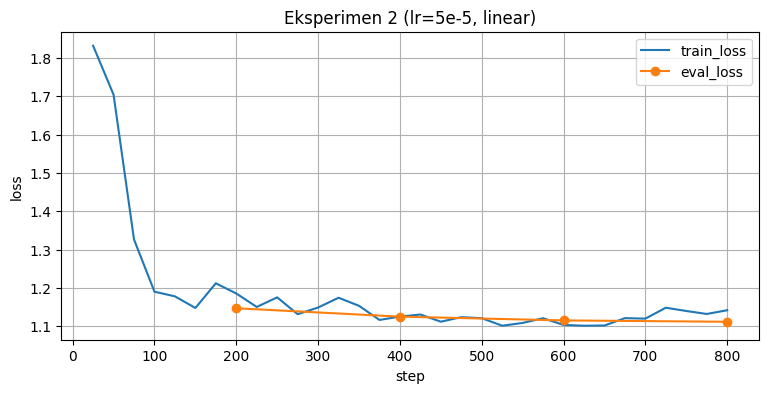

Final eval_loss Exp 2: 1.1112960577011108


Unsloth: Restored added_tokens_decoder metadata in adapter_exp2/tokenizer_config.json.


('adapter_exp2/tokenizer_config.json',
 'adapter_exp2/chat_template.jinja',
 'adapter_exp2/tokenizer.json')

In [ ]:
final_eval_exp2 = plot_loss(trainer2, "Eksperimen 2 (lr=5e-5, linear)")
print("Final eval_loss Exp 2:", final_eval_exp2)

model.save_pretrained("adapter_exp2")
tokenizer.save_pretrained("adapter_exp2")

### 7.3 Perbandingan Hasil Eksperimen

In [ ]:
results = {"exp1": final_eval_exp1, "exp2": final_eval_exp2}
best_exp = min(results, key=results.get)
print("Ringkasan eval_loss akhir :", results)
print("Eksperimen terbaik        :", best_exp)

Ringkasan eval_loss akhir : {'exp1': 1.0951815843582153, 'exp2': 1.1112960577011108}
Eksperimen terbaik        : exp1


**Analisis (lengkapi setelah training):** Kedua eksperimen menunjukkan pola pembelajaran yang sehat: train_loss turun tajam pada ±100 step pertama lalu melandai, dan eval_loss terus menurun secara konsisten hingga step 800 tanpa pernah berbalik naik — menandakan tidak terjadi overfitting pada kedua konfigurasi.
Pada Eksperimen 1 (lr=2e-4, warmup 50, weight_decay 0.01, cosine), train_loss turun dari ±1,66 ke kisaran 1,08–1,12, dengan eval_loss menurun dari ±1,127 (step 200) → ±1,108 (step 400) → ±1,097 (step 600) → ±1,093 (step 800). Pada Eksperimen 2 (lr=5e-5, warmup 100, weight_decay 0.1, linear), train_loss turun dari ±1,83 ke kisaran 1,10–1,15, dengan eval_loss menurun dari ±1,147 → ±1,110 (step 800).
Perbandingannya: learning rate yang lebih besar pada Eksperimen 1 membuat model belajar lebih cepat dan mencapai titik konvergensi yang lebih dalam pada anggaran 800 steps yang sama, sementara scheduler cosine menurunkan learning rate secara bertahap di fase akhir sehingga training tetap stabil. Eksperimen 2 dengan lr yang jauh lebih kecil memang menghasilkan kurva yang halus, tetapi pembelajarannya lebih lambat sehingga eval_loss akhirnya masih tertinggal ±0,017 dari Eksperimen 1. Selisih (gap) antara train_loss dan eval_loss pada kedua eksperimen sama-sama kecil, sehingga tidak ada indikasi overfitting yang membedakan keduanya.
Kesimpulan: Eksperimen 1 (lr=2e-4, cosine) menghasilkan eval_loss akhir terendah (±1,093 vs ±1,110) dengan kurva yang tetap stabil tanpa overfitting, sehingga model dari Eksperimen 1 dipilih sebagai model final untuk di-merge dan di-push ke Hugging Face.

## 8. Push Model Terbaik ke Hugging Face (`merged_16bit`)

Adapter dari eksperimen terbaik dimuat kembali, lalu di-*push* ke Hugging Face dengan `push_to_hub_merged` metode **`merged_16bit`** agar dapat dipanggil kembali pada tahap GRPO & inferensi RAG.

> ⚠️ Pastikan repositori bersifat **PUBLIC** (cek di halaman repo → Settings) — link Private menyebabkan submission **ditolak**.

In [ ]:
BEST_ADAPTER = "adapter_exp1" if best_exp == "exp1" else "adapter_exp2"

# Bersihkan memori sebelum memuat adapter terbaik
del trainer2, model, tokenizer
gc.collect()
torch.cuda.empty_cache()

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=BEST_ADAPTER, max_seq_length=MAX_SEQ_LENGTH, dtype=None, load_in_4bit=True,
)
print(f"Adapter terbaik '{BEST_ADAPTER}' berhasil dimuat.")

==((====))==  Unsloth 2026.7.2: Fast Qwen2 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Adapter terbaik 'adapter_exp1' berhasil dimuat.


In [ ]:
FT_REPO = f"{HF_USERNAME}/qwen2.5-3b-chat-alpaca-indonesian"

model.push_to_hub_merged(
    FT_REPO,
    tokenizer,
    save_method = "merged_16bit",           # WAJIB: metode merged_16bit
    token       = os.environ["HF_TOKEN"],   # token dari environment variable
)
print(f"Model berhasil diunggah: https://huggingface.co/{FT_REPO}")

config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in justasamthing/qwen2.5-3b-chat-alpaca-indonesian/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub


Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...0002-of-00002.safetensors:   0%|          |  601kB / 1.21GB            


Unsloth: Merging weights into 16bit: 100%|██████████| 2/2 [03:45<00:00, 112.61s/it]


Unsloth: Merge process complete. Saved to `/content/justasamthing/qwen2.5-3b-chat-alpaca-indonesian`
Model berhasil diunggah: https://huggingface.co/justasamthing/qwen2.5-3b-chat-alpaca-indonesian


## 9. Uji Cepat Model Hasil Fine-tuning

In [ ]:
FastLanguageModel.for_inference(model)

messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user",   "content": "Jelaskan secara singkat apa itu perjanjian kerja waktu tertentu (PKWT)."},
]
inputs = tokenizer.apply_chat_template(
    messages, tokenize=True, add_generation_prompt=True, return_tensors="pt"
).to("cuda")

outputs = model.generate(
    input_ids=inputs, max_new_tokens=300,
    temperature=0.7, top_p=0.9, do_sample=True,
    pad_token_id=tokenizer.eos_token_id,
)
print(tokenizer.decode(outputs[0][inputs.shape[1]:], skip_special_tokens=True))

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Both `max_new_tokens` (=300) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Perjanjian kerja waktu tertentu (PKWT) adalah perjanjian di mana pekerja diizinkan bekerja di suatu tempat dengan batas waktu tertentu. PKWT biasanya digunakan untuk pekerjaan yang memerlukan keberadaan fisik di tempat kerja, seperti pekerjaan administratif atau manajemen. PKWT dapat berdurasi beberapa hari atau beberapa bulan, dan biasanya memperbolehkan pekerja untuk bekerja di tempat kerja dengan batas waktu tertentu. Perjanjian ini umumnya ditandatangani oleh karyawan dan perusahaan, dan dapat mengandung ketentuan seperti gaji, jam kerja, dan tanggal berakhirnya perjanjian.


## 10. Kesimpulan

- Dataset `Ichsan2895/alpaca-gpt4-indonesian` berhasil di-**mapping** ke Chat Template ChatML dengan token spesial. ✅
- Model dimuat dengan **QLoRA 4-bit + double quantization**, LoRA terpasang pada **Multi-Head Attention & Feed Forward Network**. ✅
- **Dua eksperimen** SFTTrainer @ **800 steps** dengan `eval_strategy="steps"` + logging WandB selesai tanpa OOM. ✅
- Model terbaik di-*push* ke Hugging Face (**public**) dengan `merged_16bit`. ✅

Lanjut ke **Notebook 2 (GRPO)** untuk level Advanced.